# Equity return predictability

This notebook tests whether information available at month-end predicts future market excess returns for pension-fund and other long-horizon asset-allocation managers. It reproduces the CFM301 Chapter 8 table at 1-quarter, 1-year, 2-year, and 5-year horizons using local submitted data only.

The market series is CRSP value-weighted total return (`vwretd`), not `vwretx`. Future returns overlap at longer horizons, so t-statistics use Newey-West/HAC covariance with `horizon - 1` lags.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
DATA_DIR = Path('Predictor Data')
START_DATE = '1926-01-31'

def read_series(filename, value_column, date_column='observation_date'):
    frame = pd.read_csv(DATA_DIR / filename, parse_dates=[date_column])
    frame['date'] = frame[date_column].dt.to_period('M').dt.to_timestamp('M')
    return frame[['date', value_column]].drop_duplicates('date').set_index('date').sort_index()

market = pd.read_csv(DATA_DIR / 'market_data_full_history_2025.csv', parse_dates=['date'])
market['date'] = market['date'].dt.to_period('M').dt.to_timestamp('M')
market = market.drop_duplicates('date').set_index('date').sort_index()
crsp = pd.read_csv(DATA_DIR / 'Market_Dividends_Returns.csv', parse_dates=['caldt'])
crsp['date'] = crsp['caldt'].dt.to_period('M').dt.to_timestamp('M')
crsp = crsp.drop_duplicates('date').set_index('date').sort_index()
data = market[['dividend_yield (annual)', 'earnings_yield (annual)']].rename(columns={'dividend_yield (annual)': 'dividend_yield', 'earnings_yield (annual)': 'earnings_yield'})
data = data.join(crsp[['vwretd']].rename(columns={'vwretd': 'market_total_return'}), how='outer')

files = {
    'AAA': ('AAA.csv', 'AAA'), 'BAA': ('BAA.csv', 'BAA'),
    'CPI': ('CPIAUCSL.csv', 'CPIAUCSL'), 'oil': ('DCOILWTICO (1).csv', 'DCOILWTICO'),
    'GDP': ('GDPC1.csv', 'GDPC1'), 'GS10': ('GS10.csv', 'GS10'),
    'INDPRO': ('INDPRO.csv', 'INDPRO'), 'TB3MS': ('TB3MS.csv', 'TB3MS'),
    'UNRATE': ('UNRATE.csv', 'UNRATE'), 'VIX': ('VIXCLS.csv', 'VIXCLS')
}
for name, (filename, column) in files.items():
    data = data.join(read_series(filename, column).rename(columns={column: name}), how='outer')

cay = pd.read_csv(DATA_DIR / 'cay_current.csv', parse_dates=['date'])
cay['date'] = cay['date'].dt.to_period('M').dt.to_timestamp('M')
cay = cay.drop_duplicates('date').set_index('date')['cay=c-0.218 a-0.801y+0.441'].rename('cay')
data = data.join(cay, how='outer').sort_index().loc[pd.Timestamp(START_DATE):]

# TB3MS is an annualized percent rate; convert it to an effective monthly rate.
data['rf_monthly'] = (1 + data['TB3MS'] / 100) ** (1 / 12) - 1
data['market_excess'] = (1 + data['market_total_return']) / (1 + data['rf_monthly']) - 1
data.head()

,dividend_yield,earnings_yield,market_total_return,AAA,BAA,CPI,oil,GDP,GS10,INDPRO,TB3MS,UNRATE,VIX,cay,rf_monthly,market_excess
date,,,,,,,,,,,,,,,,
1926-01-31,0.0482,0.0988,0.0006,4.8200,6.0900,NaN,NaN,NaN,NaN,6.4357,NaN,NaN,NaN,NaN,NaN,NaN
1926-02-28,0.0489,0.0987,-0.0330,4.7700,6.0200,NaN,NaN,NaN,NaN,6.4357,NaN,NaN,NaN,NaN,NaN,NaN
1926-03-31,0.0525,0.1058,-0.0640,4.7900,6.0500,NaN,NaN,NaN,NaN,6.5165,NaN,NaN,NaN,NaN,NaN,NaN
1926-04-30,0.0549,0.1089,0.0370,4.7400,5.9800,NaN,NaN,NaN,NaN,6.5165,NaN,NaN,NaN,NaN,NaN,NaN
1926-05-31,0.0554,0.1081,0.0121,4.7100,5.8600,NaN,NaN,NaN,NaN,6.4626,NaN,NaN,NaN,NaN,NaN,NaN


## Predictor construction and cleaning

All sources are converted to month-end dates and duplicate dates are removed before joining. The quarterly `cay` series is carried forward from the last observed quarter-end. Predictors are winsorized at the 1st and 99th percentiles within each usable estimation sample; returns are not winsorized.

In [13]:
predictors = pd.DataFrame(index=data.index)
predictors['Dividend yield'] = data['dividend_yield']
predictors['Earnings yield'] = data['earnings_yield']
predictors['Term spread (10y - 3m)'] = data['GS10'] - data['TB3MS']
predictors['Credit spread (BAA - AAA)'] = data['BAA'] - data['AAA']
predictors['Unemployment rate'] = data['UNRATE']
predictors['GDP growth (past year)'] = data['GDP'].ffill().pct_change(12, fill_method=None)
predictors['Industrial production (past year)'] = data['INDPRO'].pct_change(12, fill_method=None)
predictors['Past 1-year return'] = (1 + data['market_total_return']).rolling(12, min_periods=12).apply(np.prod, raw=True) - 1
predictors['Past volatility (last quarter)'] = data['market_total_return'].rolling(3, min_periods=3).std(ddof=1) * np.sqrt(12)
predictors['Inflation (past year)'] = data['CPI'].pct_change(12, fill_method=None)
predictors['Oil price (past-year change)'] = data['oil'].pct_change(12, fill_method=None)
predictors['Risk-free rate'] = data['TB3MS'] / 100
predictors['VIX'] = data['VIX']
predictors['Consumption-wealth ratio (cay)'] = data['cay'].ffill()
returns = data['market_excess'].rename('future_excess_return')
missing_before = predictors.isna().sum().rename('missing_values')
print(f'Analysis dates: {data.index.min():%Y-%m} to {data.index.max():%Y-%m}')
print(f'Duplicate month-end observations removed: {int(data.index.duplicated().sum())}')
display(missing_before.to_frame().sort_values('missing_values', ascending=False))

Analysis dates: 1926-01 to 2026-10
Duplicate month-end observations removed: 0


,missing_values
Oil price (past-year change),860
VIX,815
Term spread (10y - 3m),328
Consumption-wealth ratio (cay),314
Unemployment rate,266
Inflation (past year),266
GDP growth (past year),264
Risk-free rate,97
Past 1-year return,33
Past volatility (last quarter),24


In [14]:
HORIZONS = {'1 quarter': 3, '1 year': 12, '2 years': 24, '5 years': 60}

def future_compounded_return(monthly_returns, horizon):
    return (1 + monthly_returns).rolling(horizon, min_periods=horizon).apply(np.prod, raw=True).shift(-horizon)

def winsorize(series):
    lower, upper = series.quantile([0.01, 0.99])
    return series.clip(lower=lower, upper=upper), int((series < lower).sum() + (series > upper).sum())

def predictability_row(predictor, horizon):
    sample = pd.concat([predictor.rename('x'), future_compounded_return(returns, horizon).rename('y')], axis=1).dropna()
    sample['x'], winsorized = winsorize(sample['x'])
    model = sm.OLS(sample['y'], sm.add_constant(sample['x']))
    fitted = model.fit(cov_type='HAC', cov_kwds={'maxlags': horizon - 1, 'use_correction': True})
    return sample['x'].corr(sample['y']), fitted.tvalues['x'], len(sample), winsorized

rows = []
for predictor_name in predictors.columns:
    row = {'Predictor': predictor_name}
    for horizon_name, horizon in HORIZONS.items():
        correlation, t_stat, observations, winsorized = predictability_row(predictors[predictor_name], horizon)
        row[f'{horizon_name} correlation'] = correlation
        row[f'{horizon_name} t-stat'] = t_stat
        row[f'{horizon_name} N'] = observations
        row[f'{horizon_name} winsorized'] = winsorized
    rows.append(row)

results = pd.DataFrame(rows).set_index('Predictor')
table = pd.DataFrame(index=results.index)
for horizon_name in HORIZONS:
    table[horizon_name] = results[f'{horizon_name} correlation'].map(lambda value: f'{value:.2f}') + ' (' + results[f'{horizon_name} t-stat'].map(lambda value: f'{value:.2f}') + ')'
display(table.style.set_caption('Correlation with future excess return; HAC t-statistic in parentheses'))

,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.11 (2.40),0.25 (3.06),0.34 (3.28),0.53 (3.87)
Earnings yield,0.09 (2.03),0.21 (2.69),0.27 (2.64),0.42 (2.31)
Term spread (10y - 3m),0.08 (1.63),0.17 (2.06),0.21 (2.45),0.38 (3.15)
Credit spread (BAA - AAA),0.07 (1.08),0.14 (1.62),0.13 (1.05),0.09 (0.65)
Unemployment rate,0.15 (3.28),0.22 (2.78),0.14 (1.34),0.22 (1.26)
GDP growth (past year),-0.12 (-2.20),-0.25 (-2.86),-0.19 (-2.08),-0.19 (-1.49)
Industrial production (past year),-0.10 (-1.73),-0.16 (-1.72),-0.05 (-0.47),-0.00 (-0.04)
Past 1-year return,-0.04 (-0.66),-0.16 (-2.23),-0.24 (-3.88),-0.20 (-2.35)
Past volatility (last quarter),0.12 (2.48),0.06 (1.41),0.06 (1.01),0.05 (0.65)


This is the required slide-comparable table. Each cell reports the correlation between the predictor observed at time `t` and the compounded future **market excess return**. The HAC t-statistic uses `horizon - 1` lags to account for overlapping holding-period returns. Positive valuation correlations support the dividend-discount-model prediction that cheap markets have higher subsequent returns.

,1 quarter N,1 quarter clipped at 1%/99%,1 year N,1 year clipped at 1%/99%,2 years N,2 years clipped at 1%/99%,5 years N,5 years clipped at 1%/99%
Predictor,,,,,,,,
Dividend yield,1090,22,1081,22,1069,22,1033,22
Earnings yield,1090,22,1081,22,1069,22,1033,22
Term spread (10y - 3m),858,18,849,18,837,18,801,16
Credit spread (BAA - AAA),1090,22,1081,22,1069,22,1033,22
Unemployment rate,921,18,912,18,900,18,864,16
GDP growth (past year),921,18,912,18,900,18,864,18
Industrial production (past year),1090,22,1081,22,1069,22,1033,22
Past 1-year return,1090,22,1081,22,1069,22,1033,22
Past volatility (last quarter),1090,22,1081,22,1069,22,1033,22


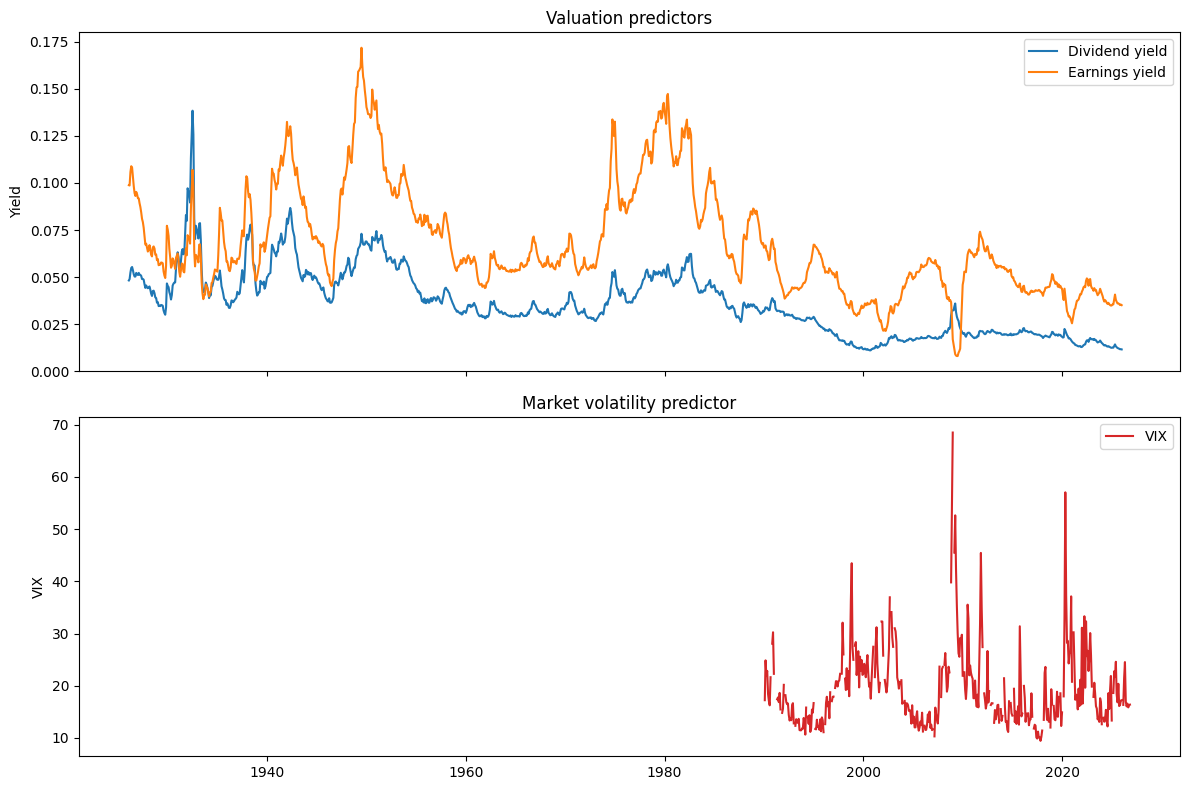

In [15]:
audit_columns = [column for horizon_name in HORIZONS for column in (f'{horizon_name} N', f'{horizon_name} winsorized')]
display(results[audit_columns].rename(columns=lambda value: value.replace(' winsorized', ' clipped at 1%/99%')))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(data.index, data['dividend_yield'], label='Dividend yield')
axes[0].plot(data.index, data['earnings_yield'], label='Earnings yield')
axes[0].set_ylabel('Yield')
axes[0].set_title('Valuation predictors')
axes[0].legend()
axes[1].plot(data.index, data['VIX'], color='tab:red', label='VIX')
axes[1].set_ylabel('VIX')
axes[1].set_title('Market volatility predictor')
axes[1].legend()
fig.tight_layout()
plt.show()

## Expected-return versus volatility predictability

The slides emphasize that volatility is more predictable than returns. This diagnostic compares the VIX at time `t` with annualized realized volatility over the following horizon; it is separate from the required return-predictability table.

In [11]:
def future_realized_volatility(monthly_returns, horizon):
    return monthly_returns.rolling(horizon, min_periods=horizon).std(ddof=1).shift(-horizon) * np.sqrt(12)

volatility_rows = []
for horizon_name, horizon in HORIZONS.items():
    sample = pd.concat([predictors['VIX'].rename('VIX'), future_realized_volatility(data['market_total_return'], horizon).rename('future_volatility')], axis=1).dropna()
    model = sm.OLS(sample['future_volatility'], sm.add_constant(sample['VIX']))
    fitted = model.fit(cov_type='HAC', cov_kwds={'maxlags': horizon - 1, 'use_correction': True})
    volatility_rows.append({'Horizon': horizon_name, 'Correlation': sample['VIX'].corr(sample['future_volatility']), 'HAC t-statistic': fitted.tvalues['VIX'], 'N': len(sample)})

volatility_table = pd.DataFrame(volatility_rows).set_index('Horizon')
display(volatility_table)
print('Convention: absolute HAC t-statistics of 2 or more are treated as statistically significant.')

,Correlation,HAC t-statistic,N
Horizon,,,
1 quarter,0.2911,4.8967,372
1 year,0.3787,4.1966,364
2 years,0.3021,3.1180,353
5 years,-0.1598,-1.0408,319


Convention: absolute HAC t-statistics of 2 or more are treated as statistically significant.
